# XGBoost — Etapa 5 do plano de previsão

**Objetivo:** prever `target_3m`, o total vendido nos três meses seguintes, para cada combinação produto × loja. Este notebook documenta exclusivamente o desenvolvimento do XGBoost e suas tentativas de correção.

O trabalho parte da régua de categoria × loja, mantém o grão mensal produto × loja × cutoff e usa somente as features já materializadas em `ml.ml_features_produto_loja_mes`.

## Resumo em palavras simples

A série individual é ruidosa e tem muitos zeros. O XGBoost puro encontra o menor erro por produto × loja, mas tende a subestimar os totais. A calibração aproxima o volume total. A reconciliação força a soma de cada categoria × loja ao total da régua. O `base_margin`, o residual logarítmico e o modelo em duas etapas foram testes para corrigir a subprevisão e os zeros; nenhum trouxe ganho suficiente sobre o equilíbrio já obtido pelo XGBoost calibrado.

## Setup e fonte dos resultados

O pipeline de modelagem não é reimplementado no notebook. `RUN_PIPELINE=True` executa `load_panel` e `run` do módulo de produção numa sessão Databricks. Para a execução reprodutível local desta documentação, `RUN_PIPELINE=False` carrega os CSVs reais da execução atual; eles servem apenas como artefatos locais e não entram no commit.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

RUN_PIPELINE = False
if RUN_PIPELINE:
    from src.analytics_ai.demand_xgboost import BASELINE, FEATURES, HORIZON, run, load_panel
    from src.analytics_ai.run_demand_xgboost import create_spark_session
else:
    BASELINE = 'baseline_pred_categoria_local_idx_trend'
    FEATURES = ('categoria_local_avg_12m', 'season_sum_next_3m', 'growth_12m', 'trend_factor', BASELINE)
    HORIZON = 3

# O notebook pode ser aberto a partir da raiz do projeto, do VS Code ou de
# notebooks/ml. Procuramos a raiz que contém os artefatos reais da execução.
PROJECT_ROOT = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / 'metricas_xgboost_offset_duas_etapas.csv').exists()),
    Path.cwd(),
)
METRICS_CSV = PROJECT_ROOT / 'metricas_xgboost_offset_duas_etapas.csv'
SEARCH_CSV = PROJECT_ROOT / 'busca_validacao_xgboost_offset_duas_etapas.csv'
TEST_PREDICTIONS_CSV = PROJECT_ROOT / 'previsoes_teste_xgboost_offset_duas_etapas.csv'
FORECAST_CSV = PROJECT_ROOT / 'previsoes_atuais_xgboost_offset_duas_etapas.csv'
print('Features iniciais:', FEATURES)
print('Alvo:', 'target_3m', '| horizonte:', HORIZON, 'meses')

Features iniciais: ('categoria_local_avg_12m', 'season_sum_next_3m', 'growth_12m', 'trend_factor', 'baseline_pred_categoria_local_idx_trend')
Alvo: target_3m | horizonte: 3 meses


## 1. Grão e divisão temporal

Cada linha representa `sk_product × sk_location × cutoff`. O alvo soma os três meses posteriores ao cutoff. Os seis cortes de validação são usados para escolher features, hiperparâmetros, calibrações e limiares. Os 12 últimos cortes completos ficam reservados para teste, sempre com embargo de três meses.

In [2]:
if RUN_PIPELINE:
    result = run(load_panel(create_spark_session()))
    metrics = result['test_metrics'].reset_index().assign(particao='teste')
    validation_metrics = result['validation_metrics'].reset_index().assign(particao='validacao')
    metrics = pd.concat([validation_metrics, metrics], ignore_index=True)
    test_predictions = result['test_predictions']
    forecast = result['future_predictions']
else:
    metrics = pd.read_csv(METRICS_CSV)
    test_predictions = pd.read_csv(TEST_PREDICTIONS_CSV)
    forecast = pd.read_csv(FORECAST_CSV)

test_cutoffs = sorted(pd.to_datetime(test_predictions['cutoff']).dt.date.unique())
print('Teste:', test_cutoffs[0], 'a', test_cutoffs[-1], '| cortes:', len(test_cutoffs))
print('Linhas de teste:', len(test_predictions), '| linhas de inferência:', len(forecast))
display(metrics.query("particao == 'validacao'").head(1))

Teste: 2025-06-01 a 2026-05-01 | cortes: 12
Linhas de teste: 72648 | linhas de inferência: 6054


,modelo,mae,rmse,wape,vies,wape_produto_local,wape_categoria_local,wape_local,particao
0,XGBoost puro,4.437187,5.813546,0.9245,-0.1361,0.9245,0.1588,0.1365,validacao


## 2. Experimentos do mesmo desenvolvimento

- **XGBoost puro:** prevê `target_3m` diretamente com objetivo Poisson.
- **XGBoost calibrado:** aplica o fator global escolhido na validação para reduzir a subprevisão.
- **XGBoost reconciliado:** redistribui o total da régua entre produtos usando as proporções do XGBoost.
- **XGBoost residual:** aprende `log1p(target_3m) − log1p(régua)`; foi descartado por forte viés.
- **XGBoost com `base_margin`:** inicia o Poisson na régua em escala logarítmica.
- **XGBoost em duas etapas:** classifica venda positiva e multiplica a probabilidade pela quantidade esperada quando há venda.

Todas as previsões e escolhas vêm de `src.analytics_ai/demand_xgboost.py`; o notebook apenas executa ou apresenta seus resultados.

In [3]:
model_order = ['Régua', 'XGBoost puro', 'XGBoost calibrado', 'XGBoost reconciliado',
               'XGBoost residual', 'XGBoost base_margin', 'XGBoost duas etapas']
available = [m for m in model_order if m in metrics['modelo'].unique()]
final_metrics = metrics[metrics['modelo'].isin(available)].copy()
final_metrics['modelo'] = pd.Categorical(final_metrics['modelo'], categories=available, ordered=True)
display(final_metrics.sort_values(['particao', 'modelo']))

,modelo,mae,rmse,wape,vies,wape_produto_local,wape_categoria_local,wape_local,particao
13,Régua,4.980689,6.377396,0.8657,-0.0275,0.8657,0.1191,0.0609,teste
12,XGBoost puro,4.908805,6.538234,0.8532,-0.2303,0.8532,0.2429,0.2331,teste
14,XGBoost calibrado,4.940581,6.417430,0.8588,-0.1090,0.8588,0.1557,0.1351,teste
15,XGBoost reconciliado,4.980689,6.377396,0.8657,-0.0275,0.8657,0.1191,0.0609,teste
16,XGBoost residual,5.059151,7.226460,0.8794,-0.5517,0.8794,0.5517,0.5517,teste
17,XGBoost base_margin,4.930165,6.463686,0.8569,-0.1588,0.8569,0.1887,0.1689,teste
18,XGBoost duas etapas,4.940396,6.440373,0.8587,-0.1261,0.8587,0.1733,0.1554,teste
1,Régua,4.488494,5.804257,0.9352,-0.0905,0.9352,0.1436,0.1027,validacao
0,XGBoost puro,4.437187,5.813546,0.9245,-0.1361,0.9245,0.1588,0.1365,validacao
2,XGBoost calibrado,4.531555,5.773841,0.9442,-0.0000,0.9442,0.1095,0.0520,validacao


## 3. Busca e diagnóstico das tentativas

A busca de validação registra os valores de `epsilon` do `base_margin`, os hiperparâmetros e a calibração das duas etapas. O residual aparece somente como referência da execução atual; ele não participa de nenhuma nova escolha.

In [4]:
search = pd.read_csv(SEARCH_CSV)
display(search.sort_values('pontuacao').head(10))

,max_depth,min_child_weight,learning_rate,n_estimators,subsample,reg_lambda,epsilon,pontuacao,experimento,threshold,fator,f1,shift_log,mae,rmse,wape,vies,wape_produto_local,wape_categoria_local,wape_local
9,3.0,10.0,0.05,250.0,0.9,5.0,NaN,1.1075,duas_etapas,0.2,1.164566,0.716172,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,2.0,10.0,0.05,250.0,0.9,5.0,NaN,1.1089,duas_etapas,0.2,1.151451,0.716172,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,3.0,10.0,0.10,150.0,0.9,5.0,NaN,1.1120,duas_etapas,0.2,1.173315,0.716172,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,2.0,10.0,0.05,250.0,0.9,5.0,0.010000,1.3405,base_margin,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.0,10.0,0.05,250.0,0.9,5.0,0.001000,1.3408,base_margin,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.0,10.0,0.05,250.0,0.9,5.0,0.000001,1.3411,base_margin,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3.0,10.0,0.05,250.0,0.9,5.0,0.010000,1.3417,base_margin,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3.0,10.0,0.05,250.0,0.9,5.0,0.000001,1.3461,base_margin,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,3.0,10.0,0.05,250.0,0.9,5.0,0.001000,1.3476,base_margin,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,2.0,10.0,0.05,250.0,0.9,5.0,NaN,1.3490,duas_etapas,0.2,1.000000,0.716172,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. O que o modelo precisa aprender

Antes de olhar os modelos, vale lembrar o sinal que chega ao XGBoost. `target_3m` é não negativo e concentrado em valores baixos, com muitos zeros. Por isso a régua carrega o nível mais estável de categoria × loja, enquanto o XGBoost aprende correções por produto × loja.

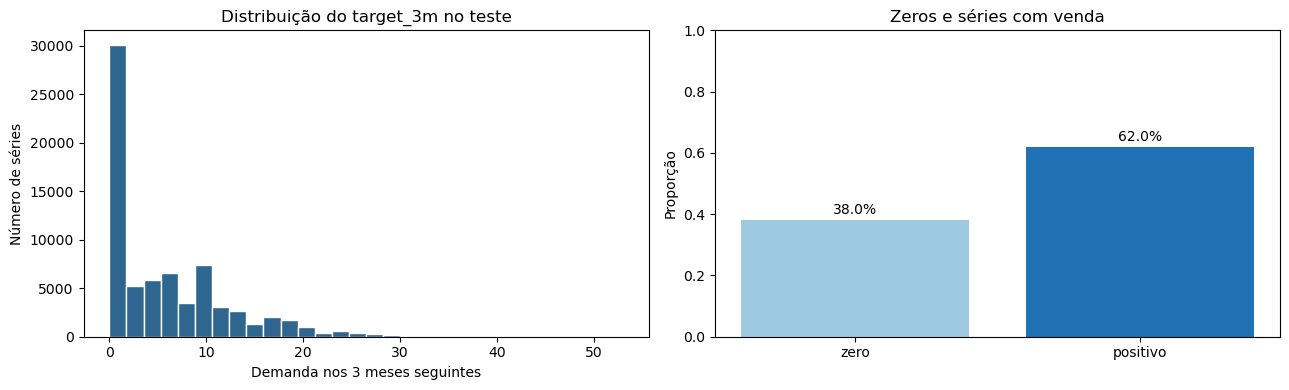

In [5]:
import matplotlib.pyplot as plt
import numpy as np

target = test_predictions['target_3m'].astype(float)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(target, bins=30, color='#2f6690', edgecolor='white')
axes[0].set_title('Distribuição do target_3m no teste')
axes[0].set_xlabel('Demanda nos 3 meses seguintes')
axes[0].set_ylabel('Número de séries')
axes[1].bar(['zero', 'positivo'], [(target == 0).mean(), (target > 0).mean()], color=['#9ecae1', '#2171b5'])
axes[1].set_ylim(0, 1)
axes[1].set_ylabel('Proporção')
axes[1].set_title('Zeros e séries com venda')
for bar in axes[1].patches: axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+.02, f'{bar.get_height():.1%}', ha='center')
plt.tight_layout()
plt.show()

## 5. A divisão temporal e o crescimento da demanda

A divisão não sorteia linhas. Cada cutoff representa o momento em que a previsão seria feita. O treino termina antes do horizonte da primeira validação; a validação escolhe tudo que pode ser ajustado; o teste permanece intacto até a avaliação final. A série temporal também permite enxergar por que a régua tende a subestimar quando a demanda cresce.

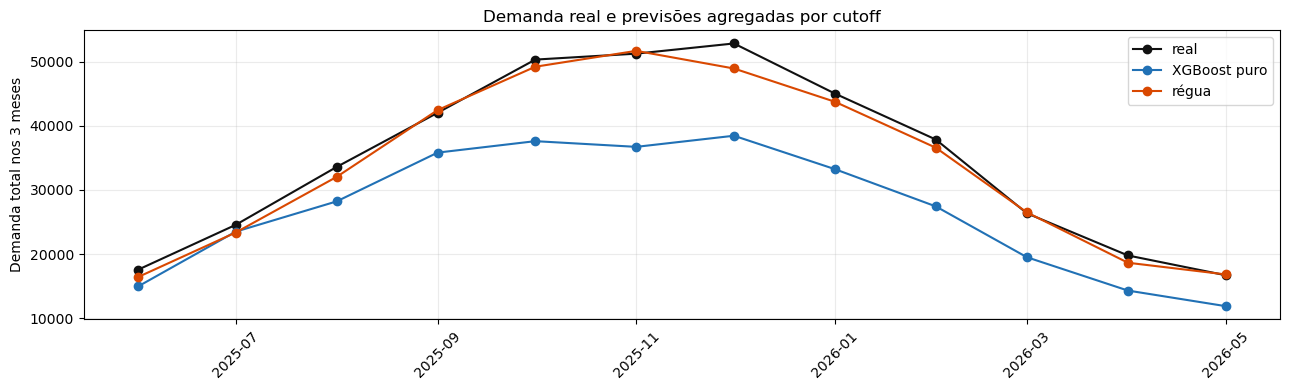

In [6]:
by_cutoff = (test_predictions.assign(cutoff=pd.to_datetime(test_predictions['cutoff']))
             .groupby('cutoff')[['target_3m', 'pred_xgboost', BASELINE]].sum().reset_index())
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(by_cutoff['cutoff'], by_cutoff['target_3m'], marker='o', label='real', color='#111111')
ax.plot(by_cutoff['cutoff'], by_cutoff['pred_xgboost'], marker='o', label='XGBoost puro', color='#2171b5')
ax.plot(by_cutoff['cutoff'], by_cutoff[BASELINE], marker='o', label='régua', color='#d94801')
ax.set_title('Demanda real e previsões agregadas por cutoff')
ax.set_ylabel('Demanda total nos 3 meses')
ax.legend()
ax.grid(alpha=.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Seleção na validação

A seleção combina quatro sinais: WAPE por produto × loja, WAPE por categoria × loja, WAPE por loja e valor absoluto do viés. Assim, uma alternativa não vence apenas por acertar o total enquanto erra as séries individuais.

,modelo,pontuacao,wape_produto_local,wape_categoria_local,wape_local,vies
2,XGBoost calibrado,1.1057,0.9442,0.1095,0.0520,-0.0000
6,XGBoost duas etapas,1.1075,0.9441,0.1109,0.0525,0.0000
1,Régua,1.2720,0.9352,0.1436,0.1027,-0.0905
3,XGBoost reconciliado,1.2720,0.9352,0.1436,0.1027,-0.0905
5,XGBoost base_margin,1.3405,0.9277,0.1559,0.1294,-0.1275
0,XGBoost puro,1.3559,0.9245,0.1588,0.1365,-0.1361
11,Categoria × loja × índice,1.4387,0.9272,0.1862,0.1636,-0.1617
10,Produto nos locais × índice,1.4472,0.9399,0.1825,0.1631,-0.1617
9,MM12 × índice,1.4988,0.9873,0.1862,0.1636,-0.1617
8,MM12,1.9043,1.0886,0.4015,0.3968,-0.0174


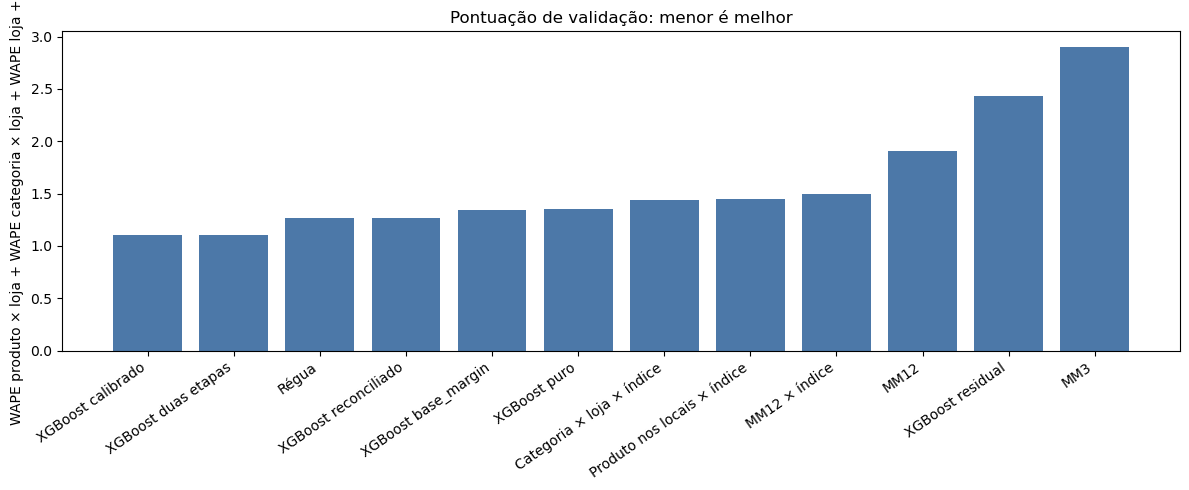

In [7]:
validation = metrics.query("particao == 'validacao'").copy()
validation['pontuacao'] = (validation['wape_produto_local'] + validation['wape_categoria_local'] + validation['wape_local'] + validation['vies'].abs())
validation = validation.sort_values('pontuacao')
display(validation[['modelo', 'pontuacao', 'wape_produto_local', 'wape_categoria_local', 'wape_local', 'vies']])
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(validation['modelo'], validation['pontuacao'], color='#4c78a8')
ax.set_title('Pontuação de validação: menor é melhor')
ax.set_ylabel('WAPE produto × loja + WAPE categoria × loja + WAPE loja + |viés|')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 7. Resultado final por nível de decisão

O painel abaixo separa o erro individual do erro agregado. Essa distinção é central: o XGBoost puro pode ganhar em produto × loja e ainda assim subestimar categoria × loja e loja.

,mae,rmse,wape_produto_local,wape_categoria_local,wape_local,vies
modelo,,,,,,
Régua,4.980689,6.377396,0.8657,0.1191,0.0609,-0.0275
XGBoost puro,4.908805,6.538234,0.8532,0.2429,0.2331,-0.2303
XGBoost calibrado,4.940581,6.417430,0.8588,0.1557,0.1351,-0.1090
XGBoost reconciliado,4.980689,6.377396,0.8657,0.1191,0.0609,-0.0275
XGBoost residual,5.059151,7.226460,0.8794,0.5517,0.5517,-0.5517
XGBoost base_margin,4.930165,6.463686,0.8569,0.1887,0.1689,-0.1588
XGBoost duas etapas,4.940396,6.440373,0.8587,0.1733,0.1554,-0.1261


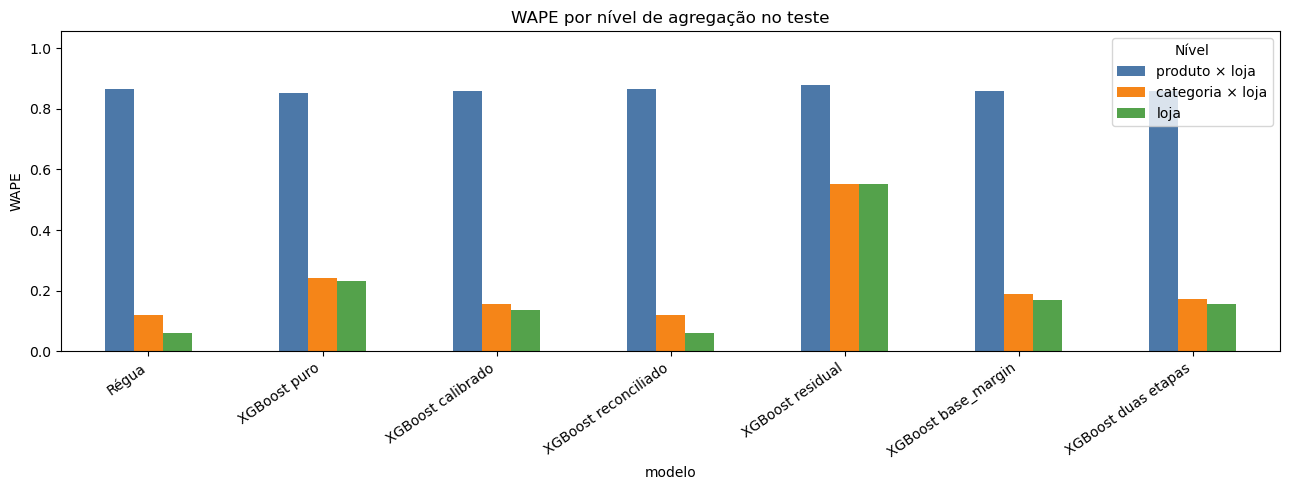

In [8]:
test = metrics.query("particao == 'teste'").copy().set_index('modelo').loc[available]
display(test[['mae', 'rmse', 'wape_produto_local', 'wape_categoria_local', 'wape_local', 'vies']])
levels = test[['wape_produto_local', 'wape_categoria_local', 'wape_local']].copy()
levels.columns = ['produto × loja', 'categoria × loja', 'loja']
ax = levels.plot(kind='bar', figsize=(13, 5), color=['#4c78a8', '#f58518', '#54a24b'])
ax.set_title('WAPE por nível de agregação no teste')
ax.set_ylabel('WAPE')
ax.set_ylim(0, max(levels.max()) * 1.2)
ax.legend(title='Nível')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 8. Estabilidade ao longo dos 12 cortes de teste

Uma média única pode esconder um mês difícil. O gráfico mostra o WAPE global por cutoff para o XGBoost puro, o calibrado, a reconciliação e as duas tentativas mais recentes.

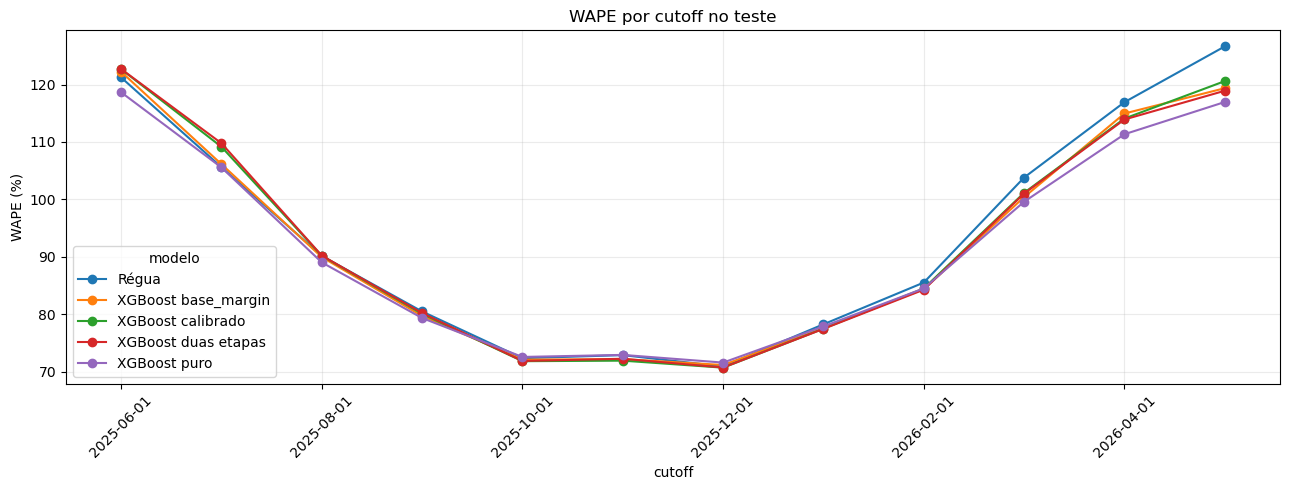

In [9]:
cutoff_metrics = []
for cutoff, part in test_predictions.groupby('cutoff'):
    rows = metrics[(metrics['particao'] == 'teste') & metrics['modelo'].isin(['XGBoost puro', 'XGBoost calibrado', 'XGBoost base_margin', 'XGBoost duas etapas'])].copy()
# A tabela por cutoff já foi produzida pelo pipeline; aqui usamos os dados de previsão para os dois modelos diretos.
for name, column in {'XGBoost puro':'pred_xgboost', 'Régua':BASELINE, 'XGBoost calibrado':'pred_calibrated', 'XGBoost base_margin':'pred_base_margin', 'XGBoost duas etapas':'pred_two_stage'}.items():
    for cutoff, part in test_predictions.groupby('cutoff'):
        actual = part['target_3m'].sum()
        cutoff_metrics.append({'cutoff': cutoff, 'modelo': name, 'wape': (part[column]-part['target_3m']).abs().sum()/actual})
cutoff_metrics = pd.DataFrame(cutoff_metrics)
pivot = cutoff_metrics.pivot(index='cutoff', columns='modelo', values='wape')
ax = (pivot * 100).plot(figsize=(13, 5), marker='o')
ax.set_title('WAPE por cutoff no teste')
ax.set_ylabel('WAPE (%)')
ax.grid(alpha=.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Previsão atual e leitura operacional

O último cutoff disponível para inferência é agosto de 2026. O gráfico mostra a distribuição das previsões atuais do XGBoost puro, calibrado e reconciliado. A reconciliação preserva as proporções do XGBoost, mas ajusta a soma de cada categoria × loja ao total da régua.

,demanda prevista nos 3 meses
XGBoost puro,36296.772531
XGBoost calibrado,42017.062772
XGBoost reconciliado,37334.204800


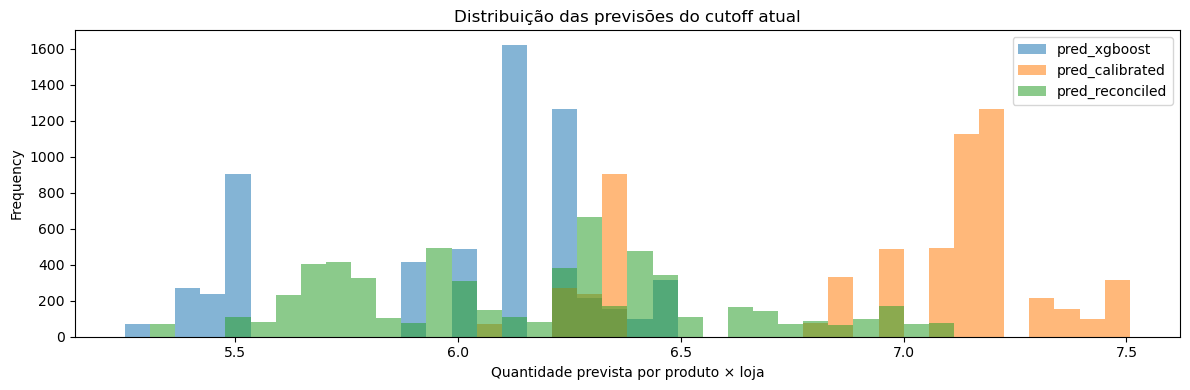

In [10]:
forecast_columns = {'XGBoost puro':'pred_xgboost', 'XGBoost calibrado':'pred_calibrated', 'XGBoost reconciliado':'pred_reconciled'}
forecast_totals = forecast[list(forecast_columns.values())].sum().rename(index={v:k for k,v in forecast_columns.items()})
display(forecast_totals.to_frame('demanda prevista nos 3 meses'))
ax = forecast[list(forecast_columns.values())].plot(kind='hist', bins=40, alpha=.55, figsize=(12, 4))
ax.set_title('Distribuição das previsões do cutoff atual')
ax.set_xlabel('Quantidade prevista por produto × loja')
plt.tight_layout()
plt.show()

## 10. Conclusão

O XGBoost puro teve o menor erro individual por produto × loja, mas subestimou os totais de categoria × loja e loja. O XGBoost calibrado foi o melhor equilíbrio entre as versões de XGBoost: reduziu a subprevisão sem depender de novas fontes ou features. A reconciliação melhora os totais ao seguir a régua, mas herda seu comportamento agregado. O residual, o `base_margin` e as duas etapas não trouxeram ganho suficiente para substituir a solução calibrada.

A tabela acima é a comparação final do desenvolvimento. Não há comparação com GLM, Regressão Linear ou outros modelos neste notebook.